# Target transfer

Run all cells with the `silscore` environment; the included caches are sufficient.

Generated from [nb2_target_transfer.py](nb2_target_transfer.py).

In [1]:
"""Plot cached performance after a training pool provenance shift.

The panels show correlations and paired changes.
"""
from __future__ import annotations

import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image

def _resolve_root() -> Path:
    file_name = globals().get("__file__")
    if file_name:
        return Path(file_name).resolve().parents[1]
    cwd = Path.cwd().resolve()
    if (cwd / "data" / "cache").is_dir():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data" / "cache").is_dir():
        return cwd.parent
    raise RuntimeError("cannot resolve Silscore root from __file__ or cwd")


ROOT = _resolve_root()
sys.path.insert(0, str(ROOT / "scripts" / "analysis"))
from prepare_oligoformer import load_metrics

SILSCORE_KEY = "modello principale (V1)"
SILSCORE_LABEL = "Silscore"
N_TRAIN = 489     # Matched training-set size.

# Required comparators.
REQUIRED = ("fisica pura", "fisica + U1", SILSCORE_KEY)

FS_TICK = 8.0
FS_LABEL = 9.0
FS_TITLE = 9.0
FS_METHOD = 8.0

FIG_W = 0.8 * 5.586        # 80% of manuscript text width, in inches.
M_LEFT, M_RIGHT = 0.80, 0.06
M_TOP, M_BOTTOM = 0.34, 0.82
GAP_X = 0.95

ORDER = [
    ("Reynolds 2004", "Reynolds", "lightgray", "o"),
    ("Ui-Tei 2004", "Ui-Tei", "darkgray", "s"),
    ("i-Score riadattato", "i-Score", "lightgreen", "D"),
    ("DSIR sparse-19", "sparse-19", "gold", "^"),
    ("DSIR spectrum-19", "spectrum-19", "orange", "v"),
    ("DSIR composite-19/19", "comp-19/19", "darkorange", "P"),
    ("DSIR composite-21/21", "comp-21/21", "sienna", "X"),
    ("OligoFormer", "OligoFormer", "tab:purple", "h"),
    ("fisica pura", "Thermo-only", "lightsteelblue", "<"),
    ("fisica + U1", "Thermo+U1", "cornflowerblue", ">"),
    (SILSCORE_KEY, SILSCORE_LABEL, "royalblue", "*"),
]


def marker_size(symbol: str) -> float:
    """Normalize visual marker areas across shapes."""
    if symbol == "*":
        return 9.0
    if symbol in {"o", "s", "D"}:
        return 5.5
    return 6.2


def main() -> int:
    with open(ROOT / "data" / "cache" / "potency_specie_per_figura.csv") as fh:
        rows = list(csv.DictReader(fh))
    val = {(r["modello"], "stessa" if "stessa" in r["test"] else "nuovi"): float(r["valore"])
           for r in rows if r["confronto"] == "pearson"}
    # Paired contrast on the same 1,453 records.
    changes = {r["modello"]: (float(r["valore"]), float(r["ic_basso"]), float(r["ic_alto"]))
           for r in rows if r["confronto"] == "caduta"}
    missing = [f"{m} / {k}" for m in REQUIRED for k in ("stessa", "nuovi")
                if (m, k) not in val]
    missing += [f"{m} / caduta" for m in REQUIRED if m not in changes]
    if missing:
        raise ValueError(f"required rows missing from V1 CSV: {missing}")

    data = load_metrics(ROOT / "data" / "cache" / "oligoformer.json")
    for row in data["comparisons"]:
        if row["model"] in ("human", "rodent"):
            val["OligoFormer", "stessa" if row["model"] == "human" else "nuovi"] = row["oligoformer_r"]
    transfer = data["species_transfer"]
    changes["OligoFormer"] = (transfer["rodent_minus_human"], transfer["ci_low"], transfer["ci_high"])

    side = (FIG_W - M_LEFT - M_RIGHT - GAP_X) / 2
    fig_h = M_TOP + side + M_BOTTOM
    fig = plt.figure(figsize=(FIG_W, fig_h), dpi=300)
    left_ax = fig.add_axes([M_LEFT / FIG_W, M_BOTTOM / fig_h, side / FIG_W, side / fig_h])
    right_ax = fig.add_axes([(M_LEFT + side + GAP_X) / FIG_W, M_BOTTOM / fig_h,
                       side / FIG_W, side / fig_h])
    visible_order = ORDER

    for name, _, color, symbol in sorted(visible_order, key=lambda r: r[0] != "OligoFormer"):
        ya, yb = val.get((name, "stessa")), val.get((name, "nuovi"))
        if ya is None or yb is None:
            continue
        left_ax.plot([0, 1], [ya, yb], "-", marker=symbol, color=color,
                markersize=marker_size(symbol), linewidth=1.3,
                markeredgecolor="0.97", markeredgewidth=0.9, zorder=3)
    left_ax.set_xlim(-0.2, 1.2)
    left_ax.set_xticks([0, 1])
    left_ax.set_xticklabels(["human inserts", "rodent inserts"], fontsize=FS_TICK)
    left_ax.set_xlabel(f"training pool provenance ($n={N_TRAIN}$)", fontsize=FS_LABEL, labelpad=2)
    left_ax.set_ylabel("Pearson\ncorrelation ($\\uparrow$)", fontsize=FS_LABEL)
    left_ax.set_title("Performance", fontsize=FS_TITLE, pad=4)
    left_ax.grid(axis="y", alpha=0.25, zorder=0)
    left_ax.tick_params(labelsize=FS_TICK)

    # Signed change: rodent-trained minus human-trained Pearson correlation.
    right_order = visible_order
    for i, (name, _, color, symbol) in enumerate(right_order):
        c, clo, chi = changes.get(name, (float("nan"),) * 3)
        if c != c:
            continue
        drop, drop_lo, drop_hi = c, clo, chi
        right_ax.errorbar(i, drop, yerr=[[drop - drop_lo], [drop_hi - drop]], fmt=symbol,
                    color=color, markersize=marker_size(symbol),
                    markeredgecolor="0.97", markeredgewidth=0.9, ecolor="0.35",
                    elinewidth=0.9, capsize=0, zorder=4)
    lows = [c[1] for c in changes.values()]
    highs = [c[2] for c in changes.values()]
    low, high = min(0, *lows), max(0, *highs)
    pad = max(0.015, 0.07 * (high - low))
    right_ax.set_ylim(low - pad, high + pad)
    right_ax.axhline(0, color="coral", lw=1.2, zorder=3)
    right_ax.set_xlim(-0.7, len(right_order) - 0.3)
    right_ax.set_xticks(range(len(right_order)))
    right_ax.set_xticklabels([e for _, e, _, _ in right_order], rotation=90, ha="center",
                       va="top", fontsize=FS_METHOD)
    right_ax.set_ylabel("change in Pearson $r$\nafter shift ($\\uparrow$)", fontsize=FS_LABEL)
    right_ax.set_title("Performance change", fontsize=FS_TITLE, pad=4)
    right_ax.grid(axis="y", alpha=0.25, zorder=0)
    right_ax.tick_params(labelsize=FS_TICK)

    out = ROOT / "output" / "figures"
    out.mkdir(parents=True, exist_ok=True)
    for extension in ("pdf", "png"):
        fig.savefig(out / f"fig_species_slope.{extension}", dpi=300)
    plt.close(fig)
    print(f"wrote {out}/fig_species_slope.pdf and .png  ({FIG_W:.2f} × {fig_h:.2f} in, "
          f"panels {side:.2f} × {side:.2f})")
    return 0

wrote ./output/figures/fig_species_slope.pdf and .png  (4.47 × 2.49 in, panels 1.33 × 1.33)


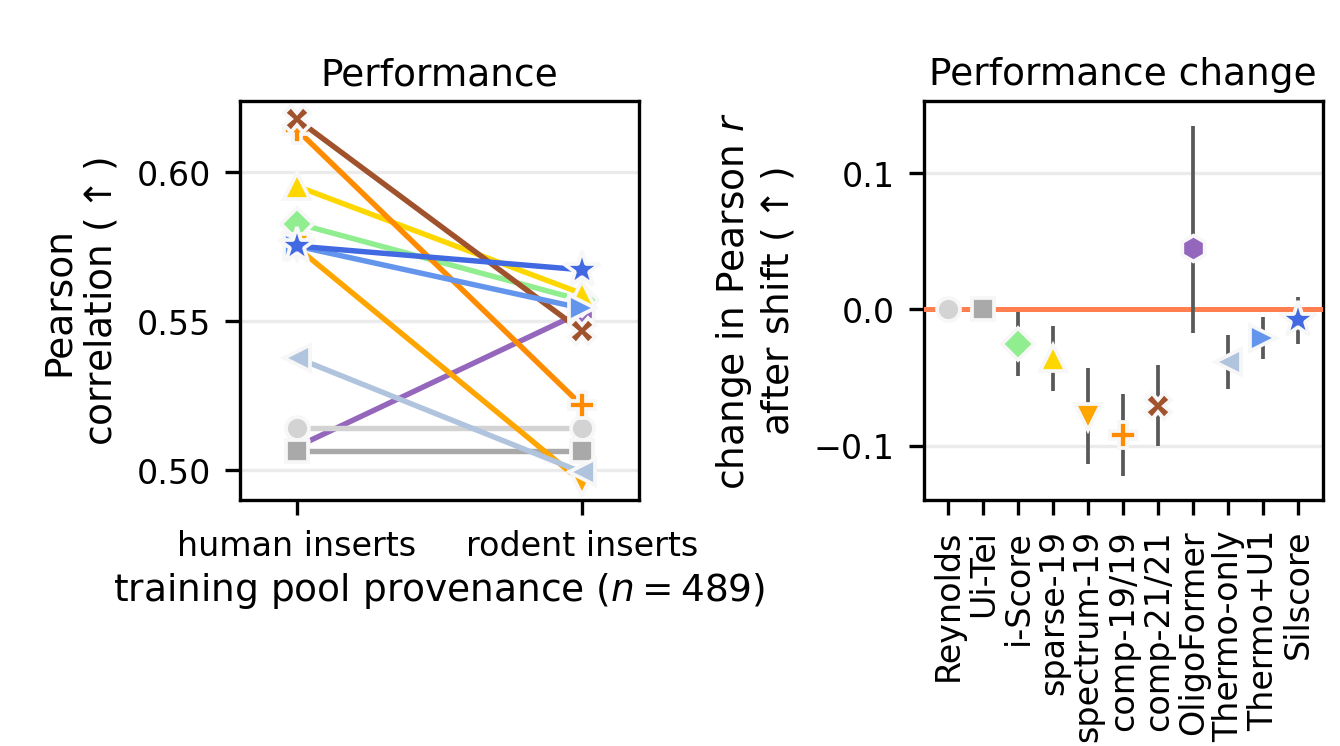

In [2]:
main()
Image(filename=str(ROOT / "output" / "figures" / "fig_species_slope.png"))